In [1]:
# Import necessary libraries and modules for the ML classification task
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Import the wine dataset
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.neural_network import MLPClassifier
# Import metrics model to check the accuracy
from sklearn import metrics
# Import train-test-split function from sklearn
from sklearn.model_selection import train_test_split

In [2]:
# Load in the wine data used within this homework assignment
wine = load_wine()

# Create a DataFrame from the wine data
data = pd.DataFrame(wine.data, columns = wine.feature_names)
data

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


As can be seen within this dataframe, the data contains a variety of chemical constituents to describe the wine and classify into classes.

In [3]:
wine = load_wine()
# Data, target_names, target, feature_names
print(wine.target_names)  # Print the target names
print (wine.feature_names)  # Print the feature names
print (wine.target)  # Print the target values, each value corresponds with a wine sample

['class_0' 'class_1' 'class_2']
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


In [4]:
# Better representation of the wine dataset with class labels included and further clarification about what all everything is
wine_df = data.copy()
# Now the datafram from above includes the class classified in
wine_df["class"] = [wine.target_names[i] for i in wine.target]

# Print a description of how many total wines there are what the measurements are
print(f"{len(wine_df)} wines, {data.shape[1]} chemical measurements")
display(wine_df.head())

# Showing the target classes and how many wines are classified into each class
print("Number of wines in each class:")
display(wine_df["class"].value_counts().sort_index())

178 wines, 13 chemical measurements


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0


Number of wines in each class:


class
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64

This representation shows that the target variable is the class that each wine has been sorted into. These classes go 0, 1, and 2 and the spread of classes is fairly even, with class 1 being the most common. The spread of how many wines have been put into each class is at the bottom of the display.

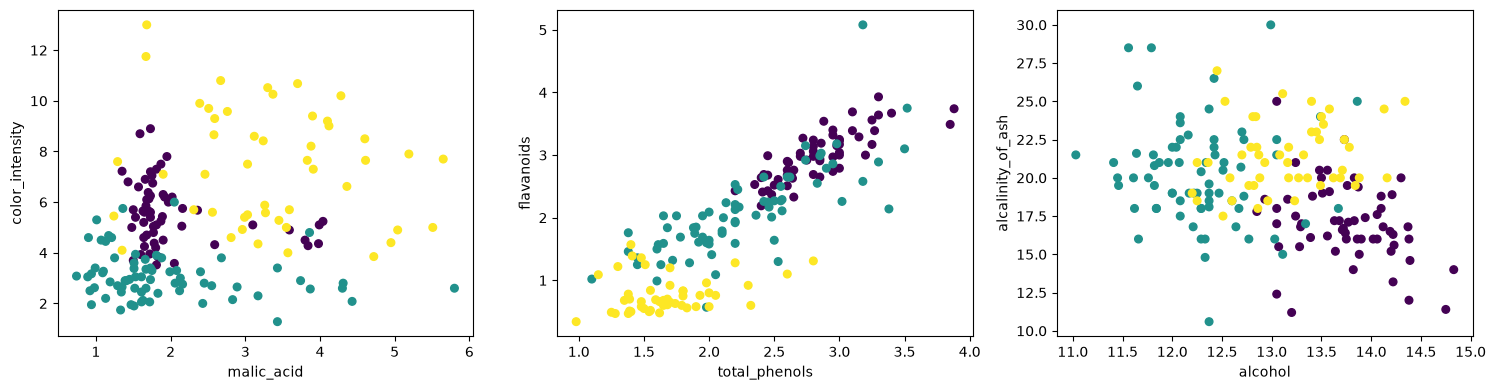

In [5]:
# Set up the figure size so the plots fit side-by-side
plt.figure(figsize=(15, 4))

# Plot 1
plt.subplot(1, 3, 1)
plt.scatter(wine.data[:,1], wine.data[:,9], s = 30, c = wine.target) # c = wine.target is the part that does the color coding
# Color intensity
plt.ylabel(wine.feature_names[9])
# Malic acid
plt.xlabel(wine.feature_names[1])

# Plot 2
plt.subplot(1, 3, 2)
plt.scatter(wine.data[:,5], wine.data[:,6], s = 30, c = wine.target) # c = wine.target is the part that does the color coding
# Flavanoids
plt.ylabel(wine.feature_names[6])
# Total phenols
plt.xlabel(wine.feature_names[5])

# Plot 3
plt.subplot(1, 3, 3)
plt.scatter(wine.data[:,0], wine.data[:,3], s = 30, c = wine.target) # c = wine.target is the part that does the color coding
# Alcalinity of Ash
plt.ylabel(wine.feature_names[3])
# Alcohol
plt.xlabel(wine.feature_names[0])

# Clean up spacing and display all three together
plt.tight_layout()
plt.show()

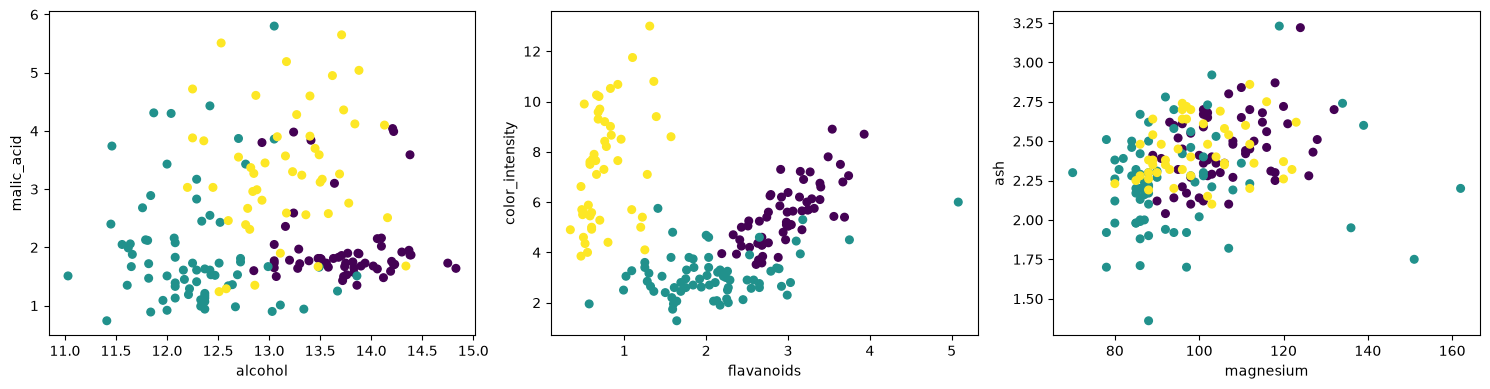

In [6]:
# Set up the figure size so the plots fit side-by-side
plt.figure(figsize=(15, 4))

# Plot 1
plt.subplot(1, 3, 1)
plt.scatter(wine.data[:,0], wine.data[:,1], s = 30, c = wine.target) # c = wine.target is the part that does the color coding
# Alcohol
plt.ylabel(wine.feature_names[1])
# Malic acid
plt.xlabel(wine.feature_names[0])

# Plot 2
plt.subplot(1, 3, 2)
plt.scatter(wine.data[:,6], wine.data[:,9], s = 30, c = wine.target) # c = wine.target is the part that does the color coding
# Color intensity
plt.ylabel(wine.feature_names[9])
# Flavanoids
plt.xlabel(wine.feature_names[6])

# Plot 3
plt.subplot(1, 3, 3)
plt.scatter(wine.data[:,4], wine.data[:,2], s = 30, c = wine.target) # c = wine.target is the part that does the color coding
# Ash
plt.ylabel(wine.feature_names[2])
# Magnesium
plt.xlabel(wine.feature_names[4])

# Clean up spacing and display all three together
plt.tight_layout()
plt.show()

These figures are here to show what individual metrics might be most useful in classification of classes. Those that show the most separation between each of the 3 classes is what I am looking for. Some notable ones include flavanoids and color intensity which show great separation between the 3, especially between class 2 (yellow) and the other two. Flavanoids and total phenols is another notable one. I will be using all variables to classify the wines here, but if you could only use a couple this analysis would help you to determine which would be the best to use.

In [7]:
# Feature matrix (inputs) from variables in the wine dataset in an object named X
X = wine.data
# Response vector (output or target) in a object named y
y = wine.target

# Print the sizes of both
print(np.shape(X))
print(np.shape(y))

(178, 13)
(178,)


In [8]:
# Split wine data into training and testing data (80:20)
# Set the random state to =4 to be reproducible.
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=4)

In [9]:
# Scale the training data
scaler = StandardScaler()
scaler.fit(X_train)

# Scale the features so that all of them can be uniformly evaluated
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

Best Architecture: 2 Layers, 4 Nodes per Layer
Best Cross-Validation Accuracy: 0.993


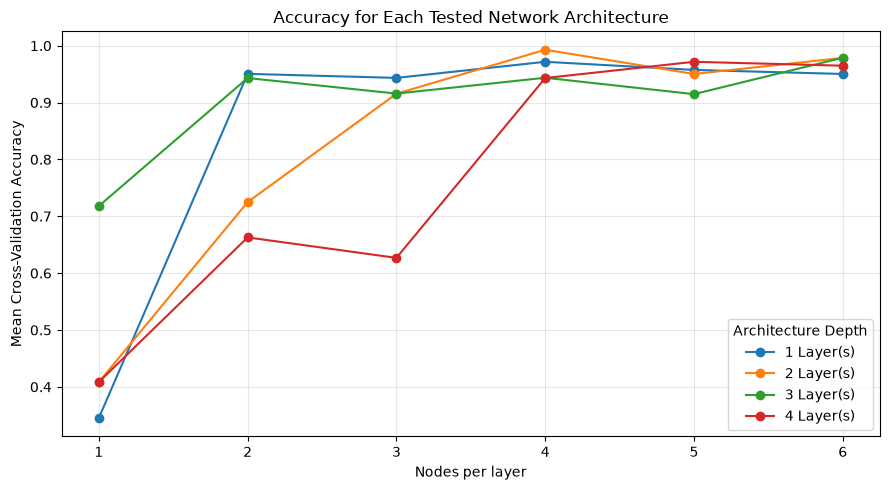

In [10]:
from sklearn.model_selection import GridSearchCV

architectures_to_test = [
    # Every architecture has the same number of nodes per layer
    (nodes,) * layers
    # Tests networks with 1 to 4 layers
    for layers in range(1, 5)
    # Tests networks with 1 to 6 nodes per layer
    for nodes in range(1, 7)
]

search = GridSearchCV(
    MLPClassifier(max_iter=1000, random_state=30),
    # Using the same number of iterations and random states for each architecture
    param_grid={"hidden_layer_sizes": architectures_to_test},
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)
search.fit(X_train, y_train)

# Describing the best architecture and giving the best accuracy score
best_architecture = search.best_params_["hidden_layer_sizes"]
print(f"Best Architecture: {len(best_architecture)} Layers, "
      f"{best_architecture[0]} Nodes per Layer")
print(f"Best Cross-Validation Accuracy: {search.best_score_:.3f}")

test_predictions = search.predict(X_test)
# Extract the architecture and its mean cross-validation accuracy
results_df = pd.DataFrame(search.cv_results_)
results_df["architecture"] = results_df["params"].apply(
    lambda params: params["hidden_layer_sizes"]
)
results_df["layers"] = results_df["architecture"].apply(len)
results_df["nodes"] = results_df["architecture"].apply(lambda arch: arch[0])

# Plot each layer count as a separate line
fig, ax = plt.subplots(figsize=(9, 5))

for layer_count, group in results_df.groupby("layers"):
    group = group.sort_values("nodes")
    ax.plot(group["nodes"], group["mean_test_score"], marker="o",
            label=f"{layer_count} Layer(s)")

# Label the axes
ax.set(
    xlabel="Nodes per layer",
    ylabel="Mean Cross-Validation Accuracy",
    title="Accuracy for Each Tested Network Architecture",
    xticks=range(1, 7),
)
ax.legend(title="Architecture Depth")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

I would use this figure to determine the optimal numbers of nodes and layers to run into the MLP classification model to get a good mixture of correct results (accuracy) and low computational power. Above 2 nodes per layer for the 1 and 3 layer runs and greater than 4 nodes per layer for the 2 and 4 layer runs all give an accuracy value over 0.9. The 2 layer run with 4 nodes per layer (4, 4) gave the best accuracy of all runs. However, I would probably use this combination because of its very high accuracy and relatively low computational power only having 2 layers, which is more important in my opinion nowadays because of the increased computational power of current computers making the computational power not as much of a problem anymore. I would also see an argument for using the 1 layer architecture with only 2 nodes (2) because it would be very computationally efficient, while only being slightly less accurate.

In [11]:
# Now build a loop to test how well different number of hidden layers performs
scores = {}
scores_list = []
l_range = range(3, 20, 1)
# The loop variable l below will iterate through the integers from 3 to 19 
# (range(3, 20, 1)).
# This defines 3 hidden layers in the network
# All 3 layers are assigned the same number of neurons (l) in every iteration.
# Iteration 1 (l = 3): 3 hidden layers with 3 neurons each
# Iteration 2 (l = 4): 3 hidden layers with 4 neurons each
# ...
# Final Iteration (l = 19): 3 hidden layers with 19 neurons each

for l in l_range:
    print(l)
    mlp = MLPClassifier(hidden_layer_sizes=(l, l, l), max_iter=1000, random_state=30)  # Keeping the iterations and random states the same
    mlp.fit(X_train, y_train)
    y_pred = mlp.predict(X_test)
    scores[l] = metrics.accuracy_score(y_test,y_pred)
    scores_list.append(metrics.accuracy_score(y_test,y_pred))

3


c:\Users\jtgal\anaconda3\envs\HW4\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


4
5


c:\Users\jtgal\anaconda3\envs\HW4\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


6
7
8
9
10
11
12
13
14
15
16
17
18
19


Text(0.5, 1.0, 'Model Accuracy vs. Number of Nodes per Layer')

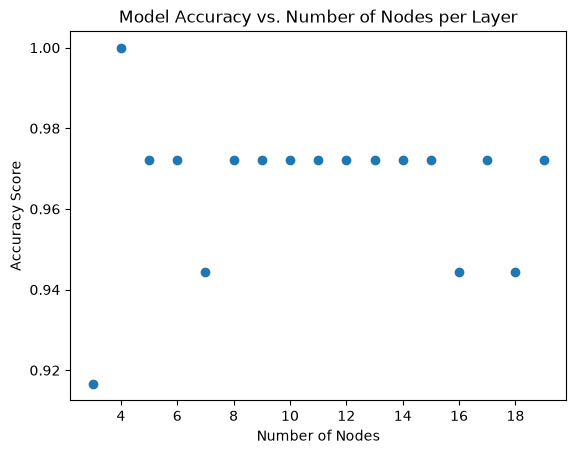

In [12]:
# Plot the model accuracy for each value of l
plt.scatter(l_range,scores_list)
plt.xlabel('Number of Nodes')
plt.ylabel('Accuracy Score')
plt.title('Model Accuracy vs. Number of Nodes per Layer')

In [13]:
# Now build the neural network using MLPClassifier
# MLPClassifier stands for Multi-layer Perceptron classifier

# https://analyticsindiamag.com/a-beginners-guide-to-scikit-learns-mlpclassifier/

# The following code will create a classifier with three layers of 10 nodes each
# max_iter refers to the number of epochs, one epoch is a combination of one cycle of 
# Feed-forward and back propagation phase
mlp = MLPClassifier(hidden_layer_sizes=(5, 5, 5), max_iter=1000, random_state=30)

# Now fit the classifer to the training data
mlp.fit(X_train, y_train)

# Try making some predictions using your classifier
predictions = mlp.predict(X_test)

# Now look at the accuracy of your predictions
print(confusion_matrix(y_test, predictions)) # Confusion Matrix

# We will use the confusion matrix to determine the accuracy which is measured as the total 
# Number of correct predictions divided by the total number of predictions.
accuracy = np.trace(confusion_matrix(y_test, predictions)) / np.sum(confusion_matrix(y_test, predictions))
print("Accuracy:", accuracy)

[[10  0  0]
 [ 0 13  0]
 [ 0  1 12]]
Accuracy: 0.9722222222222222


c:\Users\jtgal\anaconda3\envs\HW4\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


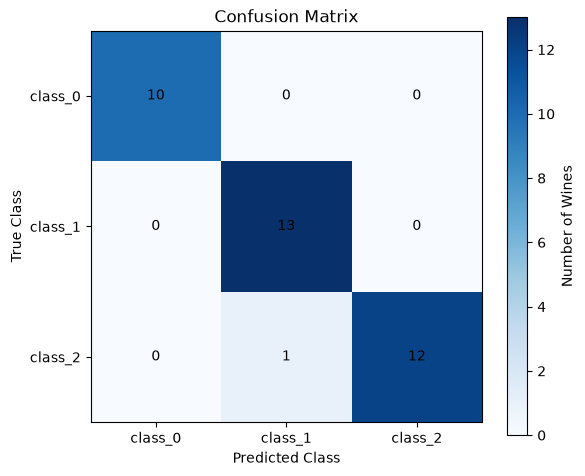

In [14]:
# Plot the confusion matrix for the MLPClassifier predictions
cm_plot = confusion_matrix(y_test, predictions, labels=[0, 1, 2])

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm_plot, cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of Wines")

# Labeling the axes
ax.set(
    xticks=np.arange(3),
    yticks=np.arange(3),
    xticklabels=wine.target_names,
    yticklabels=wine.target_names,
    xlabel="Predicted Class",
    ylabel="True Class",
    title="Confusion Matrix",
)

for row in range(3):
    for col in range(3):
        ax.text(col, row, cm_plot[row, col], ha="center", va="center")

plt.tight_layout()
plt.show()

In [15]:
# Look at the accuracy of your predictions
print(classification_report(y_test,predictions)) # Classification Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.93      1.00      0.96        13
           2       1.00      0.92      0.96        13

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



This classification report from the 3-layer run with 5 nodes per layer gave a very accurate classification. Only 1 mistake was made out of the 36 total classifications, where a wine that was supposed to be in class 2 was classified as class 1. For the 3-layer runs a 4 node per layer classification could have been made that would have been even more accurate, but I chose to do 5 nodes to show how an error would impact the classification report scores. The 5 was also an "elbow" at the beginning of some very consistent values at the highest values other than 4 nodes per layer.

In [16]:
# Now build a loop to test how well different number of hidden layers performs
scores = {}
scores_list = []
l_range = range(3, 20, 1)
# The loop variable l below will iterate through the integers from 3 to 19 
# (range(3, 20, 1)).
# This defines 4 hidden layers in the network
# All 4 layers are assigned the same number of neurons (l) in every iteration.
# Iteration 1 (l = 3): 4 hidden layers with 3 neurons each
# Iteration 2 (l = 4): 4 hidden layers with 4 neurons each
# ...
# Final Iteration (l = 19): 4 hidden layers with 19 neurons each

for l in l_range:
    print(l)
    mlp = MLPClassifier(hidden_layer_sizes=(l, l, l, l), max_iter=1000, random_state=30)  # Keeping the iterations and random states the same
    mlp.fit(X_train, y_train)
    y_pred = mlp.predict(X_test)
    scores[l] = metrics.accuracy_score(y_test,y_pred)
    scores_list.append(metrics.accuracy_score(y_test,y_pred))

3


c:\Users\jtgal\anaconda3\envs\HW4\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


4


c:\Users\jtgal\anaconda3\envs\HW4\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


5
6
7
8
9
10
11
12
13
14
15
16
17
18
19


Text(0, 0.5, 'Accuracy Score')

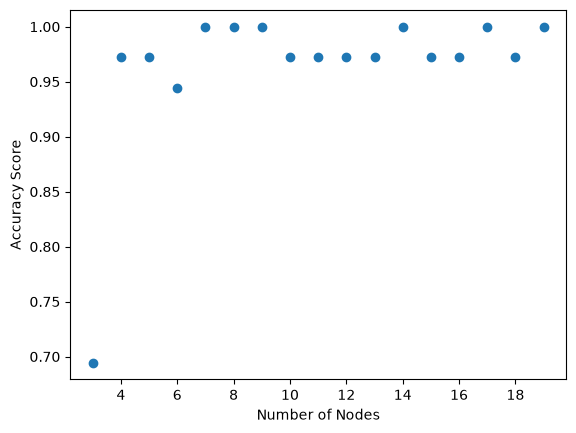

In [17]:
# Plot the model accuracy for each value of l
plt.scatter(l_range,scores_list)
plt.xlabel('Number of Nodes')
plt.ylabel('Accuracy Score')

In [18]:
# Let's go with a 4 layer model (With 7 nodes per layer)
mlp = MLPClassifier(hidden_layer_sizes=(7,7,7,7), max_iter=1000, random_state=30)
mlp.fit(X_train, y_train)

predictions1 = mlp.predict(X_test)

# Now look at the accuracy of your predictions
print(confusion_matrix(y_test, predictions1)) # Confusion Matrix

# I will use the confusion matrix to determine the accuracy which is measured as the total 
# Number of correct predictions divided by the total number of predictions
accuracy = np.trace(confusion_matrix(y_test, predictions1)) / np.sum(confusion_matrix(y_test, predictions1))
print("Accuracy:", accuracy)

[[10  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Accuracy: 1.0


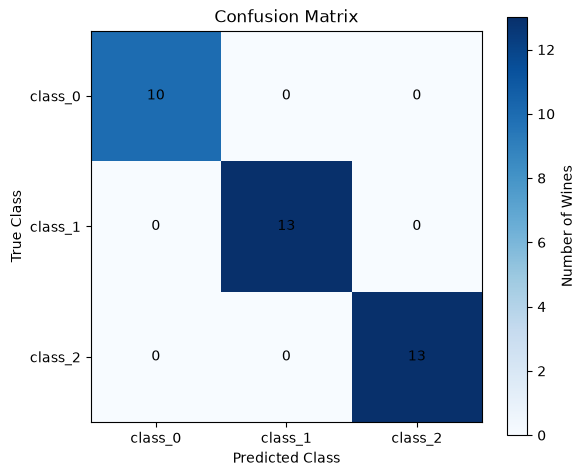

In [19]:
# Plot the confusion matrix for the MLPClassifier predictions
cm_plot = confusion_matrix(y_test, predictions1, labels=[0, 1, 2])

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm_plot, cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of Wines")

# Labeling the axes
ax.set(
    xticks=np.arange(3),
    yticks=np.arange(3),
    xticklabels=wine.target_names,
    yticklabels=wine.target_names,
    xlabel="Predicted Class",
    ylabel="True Class",
    title="Confusion Matrix",
)

for row in range(3):
    for col in range(3):
        ax.text(col, row, cm_plot[row, col], ha="center", va="center")

plt.tight_layout()
plt.show()

In [20]:
# Look at the accuracy of your predictions
print(classification_report(y_test,predictions1)) # Classification Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



For the 4 layer run I chose the number of nodes (Nodes = 7) that would give a perfect classification accuracy score. The results from the classification report reaffirm this as all values read 1.00, indicating that there were no mistakes in the classification. You could use this classification, but it is fairly computationally intensive. This is why for the final run I chose to use the 2 layer model with 4 nodes per layer because it gives very similar accuracy of results without being nearly as computationally intensive.

In [21]:
# Now build a loop to test how well different number of hidden layers performs
scores = {}
scores_list = []
l_range = range(3, 20, 1)
# The loop variable l below will iterate through the integers from 3 to 19 
# (range(3, 20, 1)).
# This defines 2 hidden layers in the network
# All 2 layers are assigned the same number of neurons (l) in every iteration.
# Iteration 1 (l = 3): 2 hidden layers with 3 neurons each
# Iteration 2 (l = 4): 2 hidden layers with 4 neurons each
# ...
# Final Iteration (l = 19): 2 hidden layers with 19 neurons each

for l in l_range:
    print(l)
    mlp = MLPClassifier(hidden_layer_sizes=(l, l), max_iter=1000, random_state=30)  # Keeping the iterations and random states the same
    mlp.fit(X_train, y_train)
    y_pred = mlp.predict(X_test)
    scores[l] = metrics.accuracy_score(y_test,y_pred)
    scores_list.append(metrics.accuracy_score(y_test,y_pred))

3


c:\Users\jtgal\anaconda3\envs\HW4\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


4
5
6


c:\Users\jtgal\anaconda3\envs\HW4\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


7
8
9
10
11
12
13
14
15
16
17
18
19


Text(0, 0.5, 'Accuracy Score')

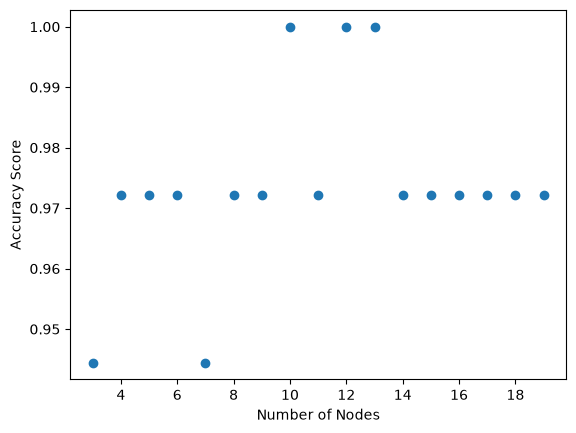

In [22]:
# Plot the model accuracy for each value of l
plt.scatter(l_range,scores_list)
plt.xlabel('Number of Nodes')
plt.ylabel('Accuracy Score')

In [23]:
# Let's go with a 2 layer model (4 nodes per layer)
mlp = MLPClassifier(hidden_layer_sizes=(4,4), max_iter=1000, random_state=30)
mlp.fit(X_train, y_train)

predictions2 = mlp.predict(X_test)

# Now look at the accuracy of your predictions
print(confusion_matrix(y_test, predictions2)) # Confusion Matrix

# We will use the confusion matrix to determine the accuracy which is measured as the total 
# Number of correct predictions divided by the total number of predictions
accuracy = np.trace(confusion_matrix(y_test, predictions2)) / np.sum(confusion_matrix(y_test, predictions2))
print("Accuracy:", accuracy)

[[10  0  0]
 [ 0 13  0]
 [ 0  1 12]]
Accuracy: 0.9722222222222222


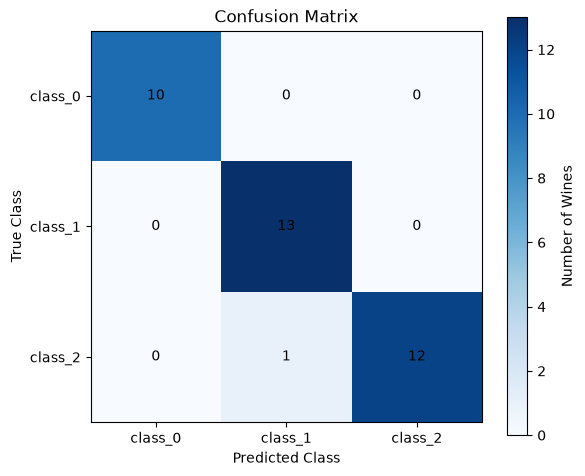

In [24]:
# Plot the confusion matrix for the MLPClassifier predictions
cm_plot = confusion_matrix(y_test, predictions2, labels=[0, 1, 2])

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm_plot, cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of Wines")

# Label the axes
ax.set(
    xticks=np.arange(3),
    yticks=np.arange(3),
    xticklabels=wine.target_names,
    yticklabels=wine.target_names,
    xlabel="Predicted Class",
    ylabel="True Class",
    title="Confusion Matrix",
)

for row in range(3):
    for col in range(3):
        ax.text(col, row, cm_plot[row, col], ha="center", va="center")

plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import accuracy_score

# Load in the dataset
file_path = "C:/Users/jtgal/OEAS805/DATA/unknown_wine.csv"
df = pd.read_csv(file_path)

# Separate features (X) and target classes (y)
X = df.drop(columns=['target'])
y = df['target']

# Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=30
)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train the MLP Classifier
mlp = MLPClassifier(hidden_layer_sizes=(4, 4), max_iter=1000, random_state=30)
mlp.fit(X_train_scaled, y_train)

# Make predictions and calculate probabilities
predictions3 = mlp.predict(X_test_scaled)
class_probabilities = mlp.predict_proba(X_test_scaled)

# Extract the maximum probability (the confidence score for the predicted class)
predicted_confidence = np.max(class_probabilities, axis=1)

# Create a summary DataFrame to display true class, predicted class, and probability
results_df = pd.DataFrame({
    'True_Class': y_test.values,
    'Predicted_Class': predictions3,
    'Confidence_Probability': predicted_confidence
})

print("First 10 Test Predictions and Probabilities:")
print(results_df.head(10).to_string(index=False))

# Evaluate performance of the MLP Classifier with a confusion matrix
conf_matrix = confusion_matrix(y_test, predictions3)
accuracy = accuracy_score(y_test, predictions3)

print("\nConfusion Matrix:")
print(conf_matrix)
print("\nAccuracy:", accuracy)

First 10 Test Predictions and Probabilities:
 True_Class  Predicted_Class  Confidence_Probability
          1                1                0.998916
          0                0                0.953945
          2                2                0.995118
          1                1                0.998645
          2                2                0.993355
          1                1                0.996851
          2                2                0.994859
          2                2                0.999618
          0                0                0.905883
          0                0                0.958197

Confusion Matrix:
[[11  0  0]
 [ 0 16  0]
 [ 0  0  9]]

Accuracy: 1.0


The 2-layer, 4 nodes per layer classification is the one I finally decided to use from the initial exploration of nodes and layers, taking into account the accuracy score and the computational power. The confusion matrix and accuracy score indicate that I made a good choice that was going to classify the wine classes as accurately as any combination of nodes and layers could. The confusion matrix indicated that the MLP Classifier made no mistakes in classification and therefore produced an accuracy score of 1.0. I was able to use the scikit-learn function `predict_proba()` to calculate the probabilty that each wine sample belonged to the wine class it was classified into. The lowest value I saw in the first 10 values was still over 90%, which means that my model likely did a good job.